In [6]:
import pyarrow.parquet as pq
import polars as pl

# Configuration
BATCH_SIZE = 100_000
parquet_file = pq.ParquetFile("data/seq.parquet")

# Accumulators for global metrics and running averages
total_rows = 0
total_length_sum = 0
max_length_global = 0
rows_exceeding_100_total = 0
null_ts_total = 0
null_item_total = 0
null_action_total = 0
out_of_order_total = 0

print(f"Starting batch-by-batch check (Batch Size: {BATCH_SIZE:,})...\n")

# Iterate through the parquet file in batches
for batch_idx, batch in enumerate(parquet_file.iter_batches(batch_size=BATCH_SIZE)):
    # Convert PyArrow batch directly into a Polars DataFrame (zero-copy where possible)
    df = pl.from_arrow(batch)
    
    # Compute metrics for the current batch
    m = df.select(
        count=pl.len(),
        sum_len=pl.col("seq").list.len().sum(),
        max_len=pl.col("seq").list.len().max(),
        exceed_100=pl.col("seq").list.len().gt(100).sum(),
        null_ts=pl.col("seq").list.eval(pl.element().struct.field("timestamp").is_null()).list.any().sum(),
        null_item=pl.col("seq").list.eval(pl.element().struct.field("item_id").is_null()).list.any().sum(),
        null_action=pl.col("seq").list.eval(pl.element().struct.field("action_type").is_null()).list.any().sum(),
        out_of_order=pl.col("seq").list.eval(
            pl.element().struct.field("timestamp") != pl.element().struct.field("timestamp").sort()
        ).list.any().sum()
    ).row(0, named=True)
    
    # Update global/running aggregates
    total_rows += m["count"]
    total_length_sum += m["sum_len"]
    max_length_global = max(max_length_global, m["max_len"])
    rows_exceeding_100_total += m["exceed_100"]
    null_ts_total += m["null_ts"]
    null_item_total += m["null_item"]
    null_action_total += m["null_action"]
    out_of_order_total += m["out_of_order"]
    
    # Calculate current running mean length
    running_mean_len = total_length_sum / total_rows if total_rows > 0 else 0
    
    # Print progress for the current batch
    print(f"Batch {batch_idx + 1} processed: {total_rows:,} total rows checked | Running Mean Length: {running_mean_len:.2f}")

# --- Final Summary Report ---
print("\n" + "="*40)
print("FINAL VALIDATION SUMMARY")
print("="*40)
print(f"Total Rows Processed:       {total_rows:,}")
print(f"Overall Mean Length:        {total_length_sum / total_rows:.2f}")
print(f"Max Sequence Length Found:  {max_length_global}")
print(f"Rows Exceeding 100 Limit:   {rows_exceeding_100_total}")
print(f"Rows with Null Timestamps:  {null_ts_total}")
print(f"Rows with Null Item IDs:    {null_item_total}")
print(f"Rows with Null Action Types:{null_action_total}")
print(f"Rows with Out-of-Order Seq: {out_of_order_total}")
print("="*40)

Starting batch-by-batch check (Batch Size: 100,000)...

Batch 1 processed: 100,000 total rows checked | Running Mean Length: 90.08
Batch 2 processed: 200,000 total rows checked | Running Mean Length: 90.08
Batch 3 processed: 300,000 total rows checked | Running Mean Length: 90.07
Batch 4 processed: 400,000 total rows checked | Running Mean Length: 90.06
Batch 5 processed: 500,000 total rows checked | Running Mean Length: 90.06
Batch 6 processed: 600,000 total rows checked | Running Mean Length: 90.05
Batch 7 processed: 700,000 total rows checked | Running Mean Length: 90.06
Batch 8 processed: 800,000 total rows checked | Running Mean Length: 90.06
Batch 9 processed: 900,000 total rows checked | Running Mean Length: 90.06
Batch 10 processed: 1,000,000 total rows checked | Running Mean Length: 90.06
Batch 11 processed: 1,001,845 total rows checked | Running Mean Length: 90.06

FINAL VALIDATION SUMMARY
Total Rows Processed:       1,001,845
Overall Mean Length:        90.06
Max Sequence Le

Analyzing null distribution across batches...



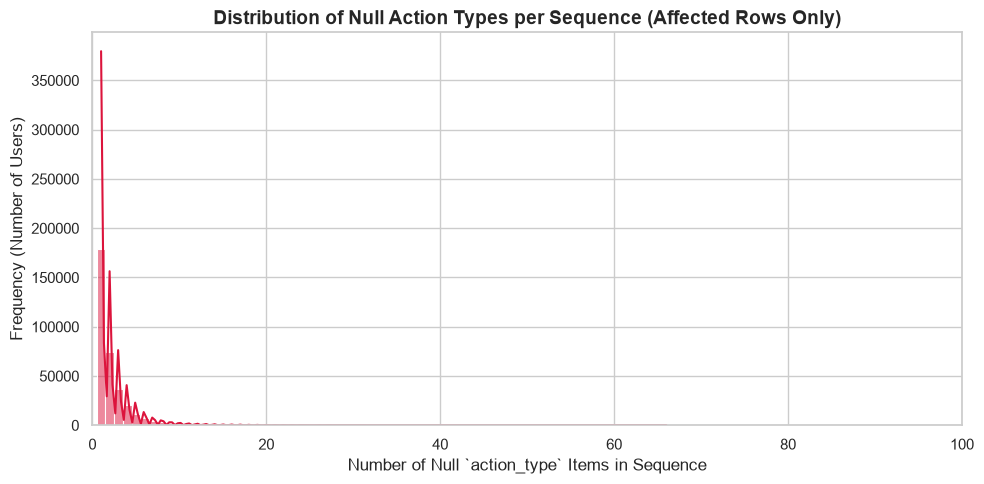

NULL CONCENTRATION SUMMARY
Total Rows Checked:         1,001,845
Rows with >= 1 Null Action: 344,817 (34.4%)
Average Nulls per Affected Row: 2.29
Median Nulls per Affected Row:  1.00


In [7]:
import pyarrow.parquet as pq
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot style
sns.set_theme(style="whitegrid")

BATCH_SIZE = 100_000
parquet_file = pq.ParquetFile("data/seq.parquet")

total_rows = 0
rows_with_any_null = 0
total_null_elements = 0
all_null_counts = []

print("Analyzing null distribution across batches...\n")

for batch_idx, batch in enumerate(parquet_file.iter_batches(batch_size=BATCH_SIZE)):
    df = pl.from_arrow(batch)
    
    # Calculate null counts per sequence for action_type
    batch_metrics = df.select(
        null_count_per_seq=pl.col("seq")
            .list.eval(pl.element().struct.field("action_type").is_null())
            .list.sum()
    )
    
    counts = batch_metrics["null_count_per_seq"].to_numpy()
    
    # Aggregate stats
    has_null = counts > 0
    rows_with_any_null += has_null.sum()
    total_null_elements += counts.sum()
    # Keep only rows that actually have nulls to see their distribution
    all_null_counts.extend(counts[has_null])
    total_rows += len(df)

# --- Plotting the Distribution ---
plt.figure(figsize=(10, 5))

# Plot histogram of null counts for affected rows
sns.histplot(all_null_counts, bins=30, kde=True, color="crimson", discrete=True)

plt.title("Distribution of Null Action Types per Sequence (Affected Rows Only)", fontsize=14, fontweight="bold")
plt.xlabel("Number of Null `action_type` Items in Sequence", fontsize=12)
plt.ylabel("Frequency (Number of Users)", fontsize=12)
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# --- Print Summary Statistics ---
null_series = pl.Series(all_null_counts)
print("="*40)
print("NULL CONCENTRATION SUMMARY")
print("="*40)
print(f"Total Rows Checked:         {total_rows:,}")
print(f"Rows with >= 1 Null Action: {rows_with_any_null:,} ({rows_with_any_null/total_rows*100:.1f}%)")
print(f"Average Nulls per Affected Row: {null_series.mean():.2f}")
print(f"Median Nulls per Affected Row:  {null_series.median():.2f}")
print("="*40)

Analyzing null distribution and tracking top max null rows across batches...



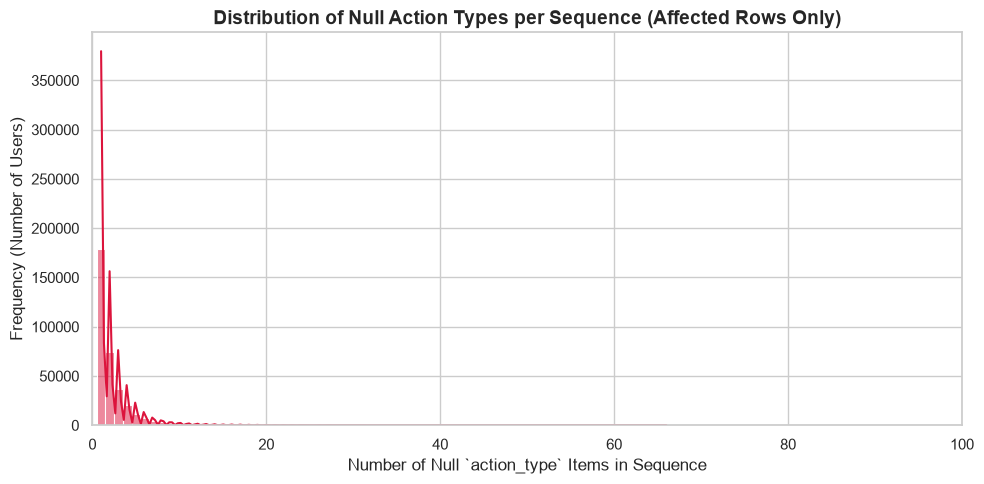

NULL CONCENTRATION SUMMARY
Total Rows Checked:             1,001,845
Rows with >= 1 Null Action:     344,817 (34.4%)
Average Nulls per Affected Row: 2.29
Median Nulls per Affected Row:  1.00

TOP 50 ROWS WITH THE LARGEST NUMBER OF NULL ACTION TYPES:
------------------------------------------------------------
Rank 1: Row Index 727,255 | Null Count: 66 / 98 items
Rank 2: Row Index 137,654 | Null Count: 61 / 94 items
Rank 3: Row Index 438,018 | Null Count: 51 / 99 items
Rank 4: Row Index 136,422 | Null Count: 49 / 91 items
Rank 5: Row Index 770,028 | Null Count: 48 / 91 items
Rank 6: Row Index 669,027 | Null Count: 46 / 100 items
Rank 7: Row Index 168,981 | Null Count: 44 / 99 items
Rank 8: Row Index 940,386 | Null Count: 44 / 100 items
Rank 9: Row Index 927,970 | Null Count: 44 / 100 items
Rank 10: Row Index 760,556 | Null Count: 44 / 100 items
Rank 11: Row Index 230,637 | Null Count: 43 / 100 items
Rank 12: Row Index 439,911 | Null Count: 43 / 99 items
Rank 13: Row Index 169,388 | Null

In [9]:
import pyarrow.parquet as pq
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import heapq

# Configure plot style
sns.set_theme(style="whitegrid")

BATCH_SIZE = 100_000
TOP_K = 50  # Number of top rows with the most nulls to show
parquet_file = pq.ParquetFile("data/seq.parquet")

total_rows = 0
rows_with_any_null = 0
total_null_elements = 0
all_null_counts = []

# Use a min-heap to keep track of the top K rows with the largest null counts
# Heap elements will be tuples: (null_count, absolute_row_index, sequence_content)
top_k_heap = []

print("Analyzing null distribution and tracking top max null rows across batches...\n")

for batch_idx, batch in enumerate(parquet_file.iter_batches(batch_size=BATCH_SIZE)):
    df = pl.from_arrow(batch)
    
    # Calculate null counts per sequence for action_type
    batch_metrics = df.select(
        seq_col=pl.col("seq"),
        null_count_per_seq=pl.col("seq")
            .list.eval(pl.element().struct.field("action_type").is_null())
            .list.sum()
    )
    
    counts = batch_metrics["null_count_per_seq"].to_numpy()
    seqs = batch_metrics["seq_col"].to_list()
    
    # Track global aggregates
    has_null = counts > 0
    rows_with_any_null += has_null.sum()
    total_null_elements += counts.sum()
    all_null_counts.extend(counts[has_null])
    
    # Track top K rows across batches
    batch_start_idx = total_rows
    for local_idx, (c, seq_val) in enumerate(zip(counts, seqs)):
        if c > 0:
            abs_idx = batch_start_idx + local_idx
            # Push to min-heap
            if len(top_k_heap) < TOP_K:
                heapq.heappush(top_k_heap, (c, abs_idx, seq_val))
            else:
                if c > top_k_heap[0][0]:
                    heapq.heapreplace(top_k_heap, (c, abs_idx, seq_val))
                    
    total_rows += len(df)

# Sort the heap items from largest to smallest null count for display
top_k_sorted = sorted(top_k_heap, key=lambda x: x[0], reverse=True)

# --- Plotting the Distribution ---
plt.figure(figsize=(10, 5))
sns.histplot(all_null_counts, bins=30, kde=True, color="crimson", discrete=True)
plt.title("Distribution of Null Action Types per Sequence (Affected Rows Only)", fontsize=14, fontweight="bold")
plt.xlabel("Number of Null `action_type` Items in Sequence", fontsize=12)
plt.ylabel("Frequency (Number of Users)", fontsize=12)
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# --- Print Summary Statistics ---
null_series = pl.Series(all_null_counts)
print("="*60)
print("NULL CONCENTRATION SUMMARY")
print("="*60)
print(f"Total Rows Checked:             {total_rows:,}")
print(f"Rows with >= 1 Null Action:     {rows_with_any_null:,} ({rows_with_any_null/total_rows*100:.1f}%)")
print(f"Average Nulls per Affected Row: {null_series.mean():.2f}")
print(f"Median Nulls per Affected Row:  {null_series.median():.2f}")
print("="*60)

# --- Print Top K Max Null Rows ---
print(f"\nTOP {TOP_K} ROWS WITH THE LARGEST NUMBER OF NULL ACTION TYPES:")
print("-" * 60)
for rank, (null_count, row_idx, seq_data) in enumerate(top_k_sorted, 1):
    seq_len = len(seq_data) if seq_data is not None else 0
    print(f"Rank {rank}: Row Index {row_idx:,} | Null Count: {null_count} / {seq_len} items")
print("-" * 60)

Analyzing the last action type across batches...



C:\Users\justin\AppData\Local\Temp\ipykernel_26732\542835612.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=categories, y=values, palette=["steelblue", "darkorange", "crimson"])


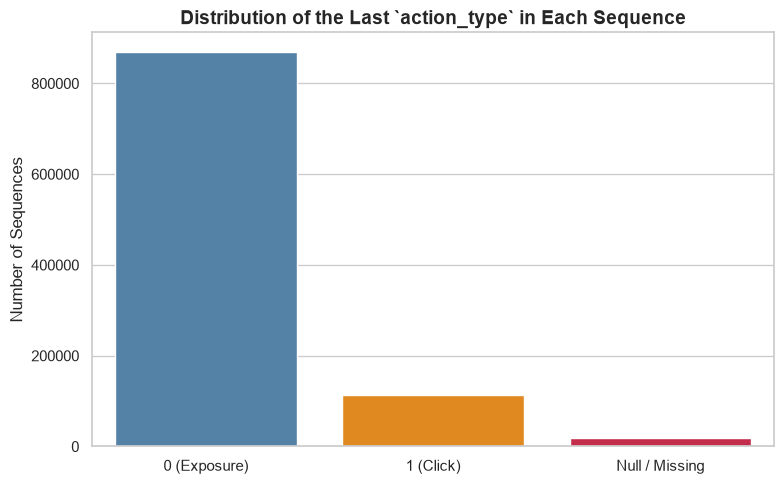

LAST ACTION TYPE DISTRIBUTION SUMMARY
Total Sequences Checked: 1,001,845

  - 0 (Exposure):        868,736 (86.71%)
  - 1 (Click):           113,822 (11.36%)
  - Null / Missing:      19,287 (1.93%)


In [11]:
import pyarrow.parquet as pq
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configure plot style
sns.set_theme(style="whitegrid")

BATCH_SIZE = 100_000
parquet_file = pq.ParquetFile("data/seq.parquet")

# Global counters for the last action type
counts = {0: 0, 1: 0, "null": 0, "other": 0}
total_rows = 0

print("Analyzing the last action type across batches...\n")

for batch_idx, batch in enumerate(parquet_file.iter_batches(batch_size=BATCH_SIZE)):
    df = pl.from_arrow(batch)
    
    # Extract the last element's action_type from each sequence list
    last_actions = (
        df.select(
            last_action=pl.col("seq").list.last().struct.field("action_type")
        )["last_action"]
        .to_numpy()
    )
    
    total_rows += len(last_actions)
    
    # Aggregate counts for this batch
    for val in last_actions:
        if val is None or (isinstance(val, float) and np.isnan(val)):
            counts["null"] += 1
        elif val == 0:
            counts[0] += 1
        elif val == 1:
            counts[1] += 1
        else:
            counts["other"] += 1

# --- Plotting the Distribution ---
plt.figure(figsize=(8, 5))
categories = ["0 (Exposure)", "1 (Click)", "Null / Missing"]
values = [counts[0], counts[1], counts["null"]]

sns.barplot(x=categories, y=values, palette=["steelblue", "darkorange", "crimson"])
plt.title("Distribution of the Last `action_type` in Each Sequence", fontsize=14, fontweight="bold")
plt.ylabel("Number of Sequences", fontsize=12)
plt.tight_layout()
plt.show()

# --- Print Summary Report ---
print("="*50)
print("LAST ACTION TYPE DISTRIBUTION SUMMARY")
print("="*50)
print(f"Total Sequences Checked: {total_rows:,}\n")
print(f"  - 0 (Exposure):        {counts[0]:,} ({counts[0]/total_rows*100:.2f}%)")
print(f"  - 1 (Click):           {counts[1]:,} ({counts[1]/total_rows*100:.2f}%)")
print(f"  - Null / Missing:      {counts['null']:,} ({counts['null']/total_rows*100:.2f}%)")
if counts["other"] > 0:
    print(f"  - Other / Unexpected:  {counts['other']:,}")
print("="*50)

Calculating click counts per sequence across batches...



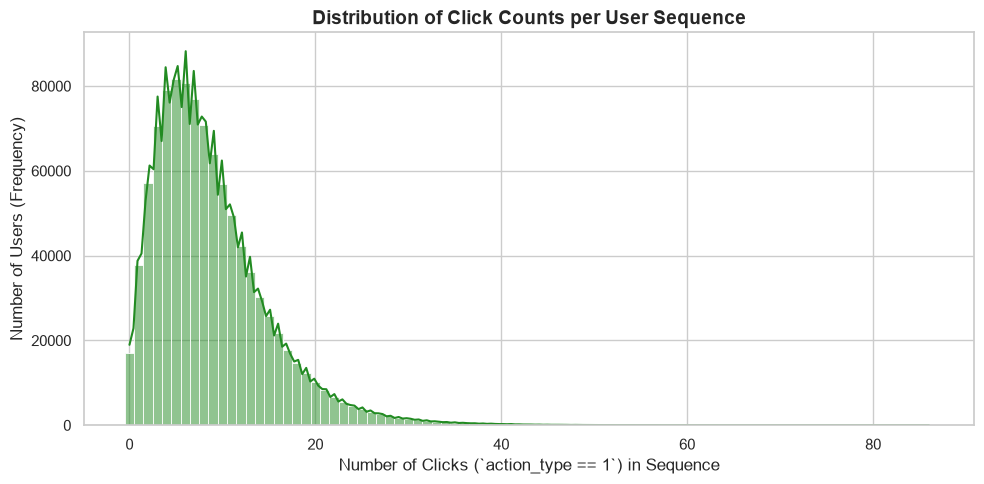

USER SEQUENCE CLICK DISTRIBUTION SUMMARY
Total Sequences Checked:         1,001,845
Average Clicks per Sequence:     8.76
Median Clicks per Sequence:      8.00
Max Clicks in a Single Sequence: 86
Min Clicks in a Single Sequence: 0
Sequences with 0 Clicks:         17,131 (1.71%)


In [13]:
import pyarrow.parquet as pq
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configure plot style
sns.set_theme(style="whitegrid")

BATCH_SIZE = 100_000
parquet_file = pq.ParquetFile("data/seq.parquet")

all_click_counts = []
total_rows = 0

print("Calculating click counts per sequence across batches...\n")

for batch_idx, batch in enumerate(parquet_file.iter_batches(batch_size=BATCH_SIZE)):
    df = pl.from_arrow(batch)
    
    # Count how many elements have action_type == 1 in each sequence list
    # (treating nulls safely as non-clicks / exposures)
    batch_click_counts = (
        df.select(
            click_count=pl.col("seq")
                .list.eval(pl.element().struct.field("action_type").fill_null(0) == 1)
                .list.sum()
        )["click_count"]
        .to_numpy()
    )
    
    all_click_counts.extend(batch_click_counts)
    total_rows += len(batch_click_counts)

# Convert to Polars Series for convenient statistical calculations
click_series = pl.Series(all_click_counts)

# --- Plotting the Distribution ---
plt.figure(figsize=(10, 5))
sns.histplot(all_click_counts, bins=30, kde=True, color="forestgreen", discrete=True)

plt.title("Distribution of Click Counts per User Sequence", fontsize=14, fontweight="bold")
plt.xlabel("Number of Clicks (`action_type == 1`) in Sequence", fontsize=12)
plt.ylabel("Number of Users (Frequency)", fontsize=12)
plt.tight_layout()
plt.show()

# --- Print Summary Statistics ---
zero_clicks_count = (click_series == 0).sum()

print("="*50)
print("USER SEQUENCE CLICK DISTRIBUTION SUMMARY")
print("="*50)
print(f"Total Sequences Checked:         {total_rows:,}")
print(f"Average Clicks per Sequence:     {click_series.mean():.2f}")
print(f"Median Clicks per Sequence:      {click_series.median():.2f}")
print(f"Max Clicks in a Single Sequence: {click_series.max()}")
print(f"Min Clicks in a Single Sequence: {click_series.min()}")
print(f"Sequences with 0 Clicks:         {zero_clicks_count:,} ({zero_clicks_count/total_rows*100:.2f}%)")
print("="*50)

In [8]:
import time
import numpy as np
from pathlib import Path
import orjson as json
from collections import Counter
import matplotlib.pyplot as plt

USE_BYTES = True

In [11]:
file_path = Path("local/2026-09-10-2/test_output/index_rqvae_prod.json")  # Replace with your actual file path

print(f"Loading '{file_path.name}' ({file_path.stat().st_size / (1024**3):.2f} GB)...")
start_time = time.time()

with open(file_path, "rb") as f:
    data = json.loads(f.read())

elapsed = time.time() - start_time
print(f"Successfully loaded {len(data):,} items in {elapsed:.2f} seconds!")


for i, (k, v) in enumerate(data.items()):
    if i >= 3:
        break
    print(f"Key: {k} | Semantic IDs: {v}")

Loading 'index_rqvae_prod.json' (0.20 GB)...
Successfully loaded 4,896,667 items in 5.61 seconds!
Key: 20000000271 | Semantic IDs: [68, 82, 30, 39, 217, 0]
Key: 20000000511 | Semantic IDs: [223, 83, 7, 222, 138, 0]
Key: 20000000520 | Semantic IDs: [243, 109, 221, 225, 54, 0]


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


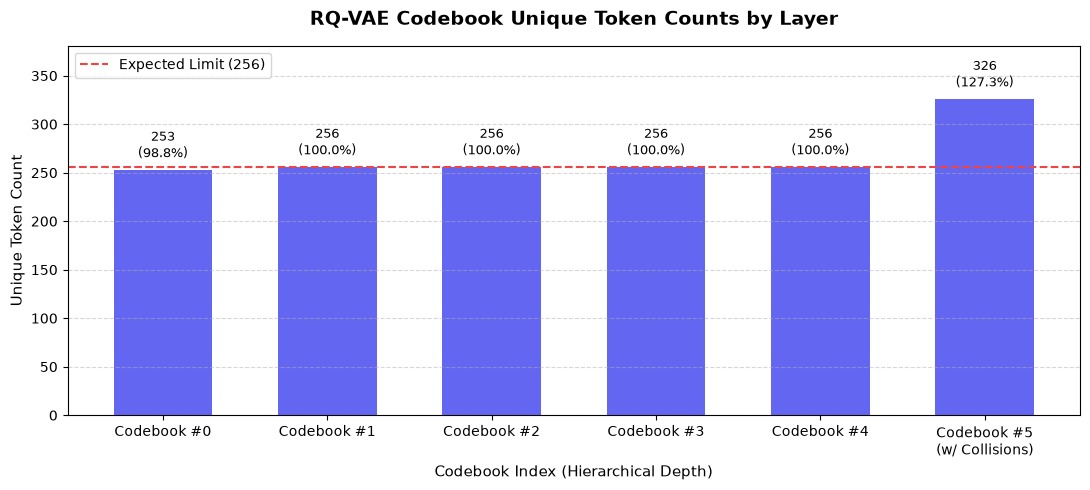

In [7]:
# Convert dictionary values to a numpy array for fast column-wise operations
all_clusters_tensor = np.array(list(data.values()))
num_items, num_codebooks = all_clusters_tensor.shape

base_codebook_size = 256  # Expected size limit
unique_counts = []
cb_labels = []

for cb_idx in range(num_codebooks):
    cb_assignments = all_clusters_tensor[:, cb_idx]
    num_unique = len(np.unique(cb_assignments))
    unique_counts.append(num_unique)
    
    if cb_idx == num_codebooks - 1:
        cb_labels.append(f"Codebook #{cb_idx}\n(w/ Collisions)")
    else:
        cb_labels.append(f"Codebook #{cb_idx}")

# Plotting Codebook Utilization (Counts & Percentages)
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(cb_labels, unique_counts, color="#6366f1", width=0.6, edgecolor="none")

# Add a dashed line for the expected 256 codebook size limit
ax.axhline(base_codebook_size, color="#ef4444", linestyle="--", linewidth=1.5, label=f"Expected Limit ({base_codebook_size})")

# Value labels on top of bars showing both count and percentage
for bar, unique in zip(bars, unique_counts):
    height = bar.get_height()
    pct = (unique / base_codebook_size) * 100.0
    ax.annotate(
        f"{unique:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),  # 6 points vertical offset
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="medium"
    )

ax.set_title("RQ-VAE Codebook Unique Token Counts by Layer", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Codebook Index (Hierarchical Depth)", fontsize=11)
ax.set_ylabel("Unique Token Count", fontsize=11)

# Give ample headroom so annotations and legend don't clash
ax.set_ylim(0, max(max(unique_counts) + 55, base_codebook_size + 60)) 

# Move legend to upper left to keep it clear of the rightmost collision bar
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Calculations completed in 17.04 seconds.


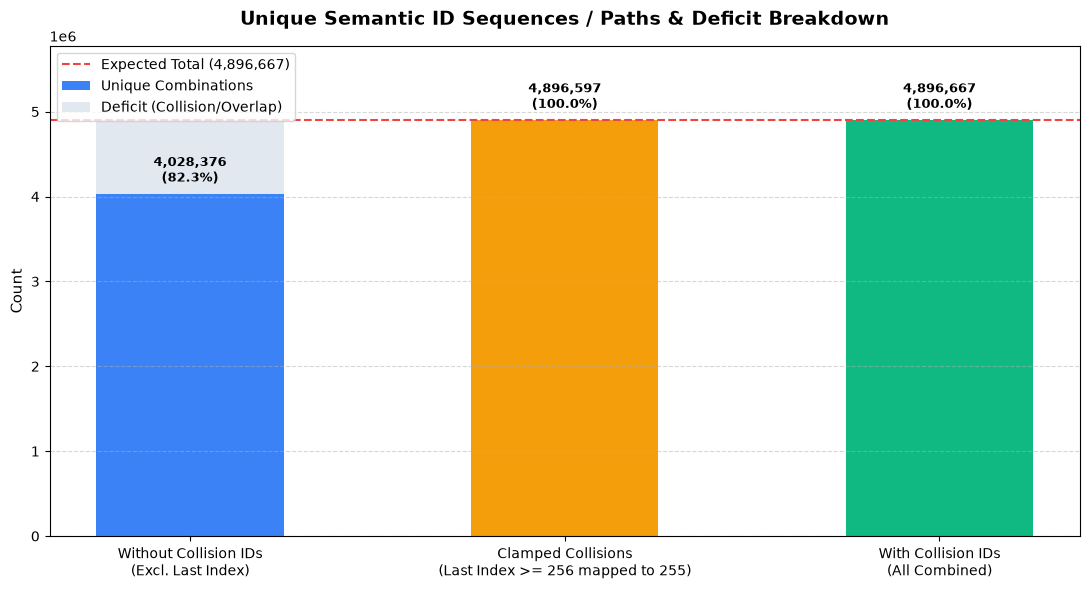

In [8]:
start_time = time.time()

total_entries = len(data)

# 1. Fast set-based unique sequence calculations
tuples_without = [tuple(v[:-1]) for v in data.values() if len(v) > 1]
unique_count_without = len(set(tuples_without))

tuples_clamped = []
for v in data.values():
    if len(v) > 0:
        lst = list(v)
        if lst[-1] >= 256:
            lst[-1] = 255
        tuples_clamped.append(tuple(lst))
unique_count_clamped = len(set(tuples_clamped))

tuples_with = [tuple(v) for v in data.values()]
unique_count_with = len(set(tuples_with))

print(f"Calculations completed in {time.time() - start_time:.2f} seconds.")

# --- Plotting Stacked Bars (Actual + Deficit to Expected Total) ---
categories = [
    "Without Collision IDs\n(Excl. Last Index)", 
    "Clamped Collisions\n(Last Index >= 256 mapped to 255)", 
    "With Collision IDs\n(All Combined)"
]

actual_counts = [unique_count_without, unique_count_clamped, unique_count_with]
deficits = [total_entries - count for count in actual_counts]

fig, ax = plt.subplots(figsize=(11, 6))

# Main bars (Actual Unique Counts)
bars_actual = ax.bar(categories, actual_counts, width=0.5, color=["#3b82f6", "#f59e0b", "#10b981"], edgecolor="none", label="Unique Combinations")
# Deficit bars (Stacked on top)
bars_deficit = ax.bar(categories, deficits, bottom=actual_counts, width=0.5, color="#e2e8f0", edgecolor="none", label="Deficit (Collision/Overlap)")

# Value labels on top of actual bars
for bar, count in zip(bars_actual, actual_counts):
    height = bar.get_height()
    pct = (count / total_entries) * 100.0
    ax.annotate(
        f"{count:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.axhline(total_entries, color="#ef4444", linestyle="--", linewidth=1.5, label=f"Expected Total ({total_entries:,})")

ax.set_title("Unique Semantic ID Sequences / Paths & Deficit Breakdown", fontsize=14, fontweight="bold", pad=15)
ax.set_ylabel("Count", fontsize=11)
ax.set_ylim(0, total_entries * 1.18)  # Headroom for annotations
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Total Entries: 4,896,667
Entries requiring clamping (>= 256): 70 (0.0014%)
Normal entries (< 256): 4,896,597 (99.9986%)


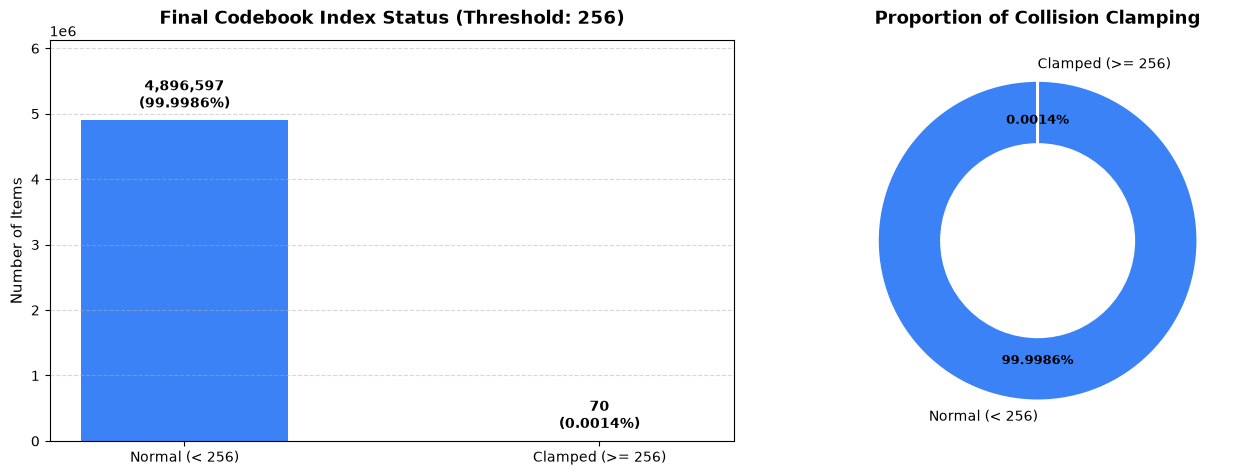

In [9]:
# --- CONFIGURABLE PARAMETERS ---
CLAMP_THRESHOLD = 256     # Threshold for collision clamping
PRECISION_DECIMALS = 4    # Number of decimal places for percentages (e.g., 2, 4, etc.)

# Count how many entries have their last semantic ID >= threshold (needing clamping)
total_entries = len(data)
clamped_entries = sum(1 for v in data.values() if len(v) > 0 and v[-1] >= CLAMP_THRESHOLD)
normal_entries = total_entries - clamped_entries

clamped_pct = (clamped_entries / total_entries) * 100.0
normal_pct = (normal_entries / total_entries) * 100.0

# Format strings dynamically based on precision parameter
pct_format_str = f"{{:.{PRECISION_DECIMALS}f}}%"

print(f"Total Entries: {total_entries:,}")
print(f"Entries requiring clamping (>= {CLAMP_THRESHOLD}): {clamped_entries:,} ({pct_format_str.format(clamped_pct)})")
print(f"Normal entries (< {CLAMP_THRESHOLD}): {normal_entries:,} ({pct_format_str.format(normal_pct)})")

# --- Plotting Breakdown Chart ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart Breakdown
categories = [f"Normal (< {CLAMP_THRESHOLD})", f"Clamped (>= {CLAMP_THRESHOLD})"]
counts = [normal_entries, clamped_entries]
colors = ["#3b82f6", "#ef4444"]

bars = ax1.bar(categories, counts, width=0.5, color=colors, edgecolor="none")
for bar, count, pct in zip(bars, counts, [normal_pct, clamped_pct]):
    height = bar.get_height()
    pct_text = pct_format_str.format(pct)
    ax1.annotate(
        f"{count:,}\n({pct_text})",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax1.set_title(f"Final Codebook Index Status (Threshold: {CLAMP_THRESHOLD})", fontsize=13, fontweight="bold", pad=12)
ax1.set_ylabel("Number of Items", fontsize=11)
ax1.set_ylim(0, max(counts) * 1.25)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# 2. Donut Chart Ratio
pie_format_str = f"%1.{PRECISION_DECIMALS}f%%"
wedges, texts, autotexts = ax2.pie(
    counts, 
    labels=categories, 
    colors=colors, 
    autopct=pie_format_str, 
    startangle=90, 
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor="white", linewidth=2)
)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight("bold")

ax2.set_title("Proportion of Collision Clamping", fontsize=13, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

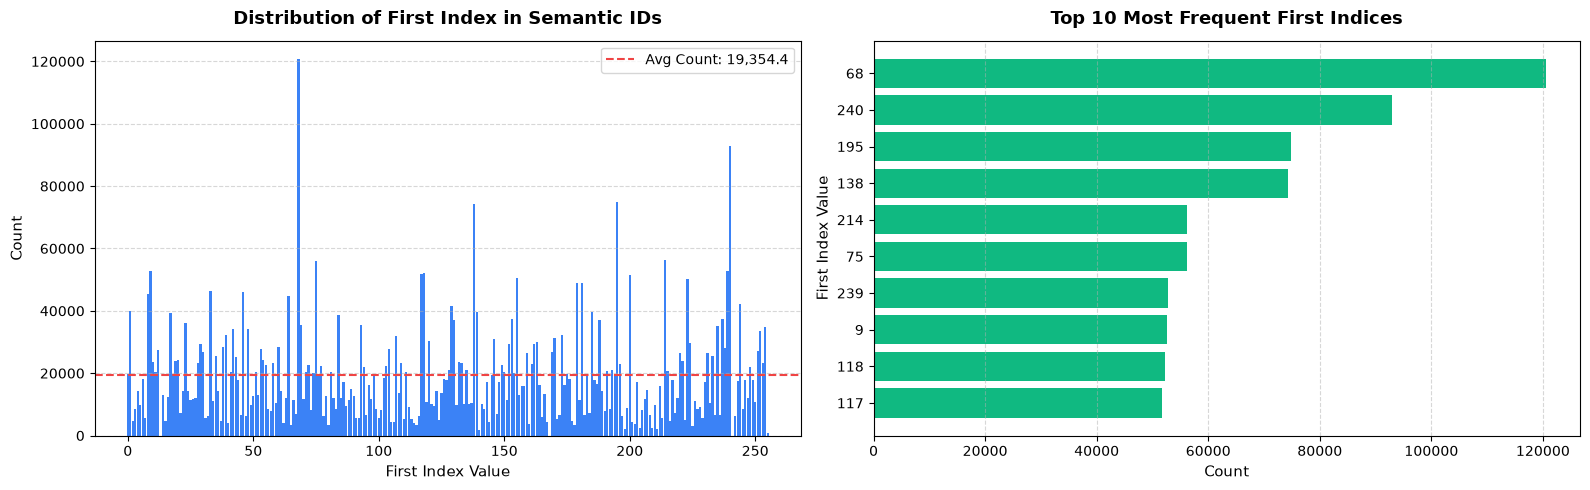

In [10]:
# Extract the first element from each semantic ID list
first_indices = [v[0] for v in data.values() if len(v) > 0]

# Count the frequencies
counts = Counter(first_indices)

# Sort by the index value for the full distribution chart
sorted_keys = sorted(counts.keys())
sorted_counts = [counts[k] for k in sorted_keys]

# Create figure with 2 subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# --- Subplot 1: Full Distribution Bar Chart with Average Dashed Line ---
ax1.bar(sorted_keys, sorted_counts, width=0.9, color="#3b82f6", edgecolor="none")
mean_count = sum(sorted_counts) / len(sorted_counts) if sorted_counts else 0
ax1.axhline(
    mean_count,
    color="#ef4444",
    linestyle="--",
    linewidth=1.5,
    label=f"Avg Count: {mean_count:,.1f}",
)

ax1.set_title("Distribution of First Index in Semantic IDs", fontsize=13, fontweight="bold", pad=12)
ax1.set_xlabel("First Index Value", fontsize=11)
ax1.set_ylabel("Count", fontsize=11)
ax1.legend(loc="upper right")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# --- Subplot 2: Horizontal Sorted Bar Chart for Top 10 Most Frequent ---
top_10 = counts.most_common(10)
# Reverse to have the highest at the top in horizontal layout
top_10_sorted = sorted(top_10, key=lambda x: x[1])
top_keys = [str(item[0]) for item in top_10_sorted]
top_vals = [item[1] for item in top_10_sorted]

ax2.barh(top_keys, top_vals, color="#10b981", edgecolor="none")
ax2.set_title("Top 10 Most Frequent First Indices", fontsize=13, fontweight="bold", pad=12)
ax2.set_xlabel("Count", fontsize=11)
ax2.set_ylabel("First Index Value", fontsize=11)
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [9]:
# Path to your exported json file
json_path = Path("data/exported_indexer/i.json")

print(f"Loading '{json_path.name}' with orjson...")
with open(json_path, "rb") as f:
    # orjson.loads takes bytes, so we read in binary mode ("rb")
    i_data = json.loads(f.read())

print(f"Type of i_data: {type(i_data)}")
print(f"Length / Number of items: {len(i_data):,}")

# Preview first few items if it's a list or dict
if isinstance(i_data, dict):
    sample_keys = list(i_data.keys())[:3]
    print(f"Sample keys: {sample_keys}")
elif isinstance(i_data, list) and len(i_data) > 0:
    print(f"First element preview: {i_data[:3]}")

Loading 'i.json' with orjson...
Type of i_data: <class 'dict'>
Length / Number of items: 4,783,154
Sample keys: ['20004268480', '20002049346', '20001902532']


In [12]:
import pandas as pd

# 1. Extract sets of OIDs
rqvae_oids = set(data.keys())
indexer_oids = set(i_data.keys())

# 2. Set Operations
only_in_rqvae = rqvae_oids - indexer_oids
only_in_indexer = indexer_oids - rqvae_oids
common_oids = rqvae_oids & indexer_oids

print(f"Total OIDs in RQ-VAE data (`data`): {len(rqvae_oids):,}")
print(f"Total OIDs in Indexer mapping (`i_data`): {len(indexer_oids):,}")
print(f"Intersection (present in both): {len(common_oids):,}")
print(f"OIDs ONLY in RQ-VAE data (missing from indexer): {len(only_in_rqvae):,}")
print(f"OIDs ONLY in Indexer mapping (missing from RQ-VAE): {len(only_in_indexer):,}")

# 3. Check for duplicate values (RIDs) in i_data to see if multiple OIDs share an RID
rid_values = list(i_data.values())
unique_rids = set(rid_values)
print(f"\nTotal RID mappings in `i_data`: {len(rid_values):,}")
print(f"Unique RIDs in `i_data`: {len(unique_rids):,}")

if len(rid_values) != len(unique_rids):
    print("⚠️ Warning: There are duplicate RIDs mapped by different OIDs in `i_data`!")
else:
    print("✅ All RIDs in `i_data` are strictly unique 1-to-1 mappings.")

Total OIDs in RQ-VAE data (`data`): 4,896,667
Total OIDs in Indexer mapping (`i_data`): 4,783,154
Intersection (present in both): 4,747,720
OIDs ONLY in RQ-VAE data (missing from indexer): 148,947
OIDs ONLY in Indexer mapping (missing from RQ-VAE): 35,434

Total RID mappings in `i_data`: 4,783,154
Unique RIDs in `i_data`: 4,783,154
✅ All RIDs in `i_data` are strictly unique 1-to-1 mappings.


In [14]:
import pandas as pd

# 1. Load the parquet file containing anonymous_cid
print("Loading mm_emb_81_32.parquet...")
mm_df = pd.read_parquet('data/mm_emb_81_32.parquet')

# Extract unique anonymous_cids as a set
rqvae_oids = set(mm_df['anonymous_cid'].dropna())
indexer_oids = set(i_data.keys())

# 2. Set Operations
only_in_rqvae = rqvae_oids - indexer_oids
only_in_indexer = indexer_oids - rqvae_oids
common_oids = rqvae_oids & indexer_oids

print(f"Total OIDs in RQ-VAE data (`mm_emb_81_32.parquet`): {len(rqvae_oids):,}")
print(f"Total OIDs in Indexer mapping (`i_data`): {len(indexer_oids):,}")
print(f"Intersection (present in both): {len(common_oids):,}")
print(f"OIDs ONLY in RQ-VAE data (missing from indexer): {len(only_in_rqvae):,}")
print(f"OIDs ONLY in Indexer mapping (missing from RQ-VAE): {len(only_in_indexer):,}")

# 3. Check for duplicate values (RIDs) in i_data to see if multiple OIDs share an RID
rid_values = list(i_data.values())
unique_rids = set(rid_values)
print(f"\nTotal RID mappings in `i_data`: {len(rid_values):,}")
print(f"Unique RIDs in `i_data`: {len(unique_rids):,}")

if len(rid_values) != len(unique_rids):
    print("⚠️ Warning: There are duplicate RIDs mapped by different OIDs in `i_data`!")
else:
    print("✅ All RIDs in `i_data` are strictly unique 1-to-1 mappings.")

Loading mm_emb_81_32.parquet...
Total OIDs in RQ-VAE data (`mm_emb_81_32.parquet`): 4,742,961
Total OIDs in Indexer mapping (`i_data`): 4,783,154
Intersection (present in both): 4,595,474
OIDs ONLY in RQ-VAE data (missing from indexer): 147,487
OIDs ONLY in Indexer mapping (missing from RQ-VAE): 187,680

Total RID mappings in `i_data`: 4,783,154
Unique RIDs in `i_data`: 4,783,154
✅ All RIDs in `i_data` are strictly unique 1-to-1 mappings.


In [15]:
parquet_path = Path("data/item_feat.parquet")

print(f"Loading '{parquet_path.name}'...")
item_feat_df = pd.read_parquet(parquet_path)

print(f"\nDataFrame Shape: {item_feat_df.shape[0]:,} rows, {item_feat_df.shape[1]} columns")

# Summary of columns, types, and non-null counts
print("\n--- Column Summary ---")
summary_df = pd.DataFrame({
    "Field Type": item_feat_df.dtypes.astype(str),
    "Non-None Values": item_feat_df.notnull().sum(),
    "Null Values": item_feat_df.isnull().sum()
})
display(summary_df)

print("\n--- Preview (First 3 Rows) ---")
display(item_feat_df.head(3))

Loading 'item_feat.parquet'...

DataFrame Shape: 4,783,154 rows, 14 columns

--- Column Summary ---


,Field Type,Non-None Values,Null Values
item_id,int64,4783154,0
100,float64,4779045,4109
101,float64,4779045,4109
102,float64,4735917,47237
112,float64,4701740,81414
114,float64,4778327,4827
115,float64,1531415,3251739
116,float64,4778146,5008
117,float64,4701740,81414
118,float64,4700703,82451



--- Preview (First 3 Rows) ---


,item_id,100,101,102,112,114,115,116,117,118,119,120,121,122
0,26,4.0,5.0,81603.0,14.0,3.0,NaN,8.0,382.0,692.0,3077.0,640.0,2011258,67985.0
1,29,4.0,17.0,28505.0,29.0,3.0,NaN,12.0,167.0,464.0,2099.0,640.0,1577026,40945.0
2,474,6.0,22.0,39459.0,29.0,3.0,543.0,2.0,33.0,519.0,3766.0,2601.0,2003579,52241.0


In [4]:
from pathlib import Path
import json
import pandas as pd

# 1. Load candidate dataset, item feature dataset, and the mapper (i.json)
candidate_path = Path("data/candidate.parquet")
item_feat_path = Path("data/item_feat.parquet")
json_path = Path("data/exported_indexer/i.json")

print(f"Loading '{candidate_path.name}', '{item_feat_path.name}', and '{json_path.name}'...")
candidate_df = pd.read_parquet(candidate_path)
item_feat_df = pd.read_parquet(item_feat_path)

with open(json_path, "rb") as f:
    # Assuming standard json or orjson (using standard json here, swap to orjson if preferred)
    i_data = json.loads(f.read())

print(f"Candidate DataFrame shape: {candidate_df.shape}")
print(f"Item Feature DataFrame shape: {item_feat_df.shape}")
print(f"Mapper (i.json) entries: {len(i_data):,}")

# 2. Extract sets and map candidate OIDs -> RIDs
candidate_oids = set(candidate_df["item_id"].astype(str))
item_feat_rids = set(item_feat_df["item_id"].astype(str))

# Map candidate OIDs to RIDs using i_data
# (Assuming i_data maps OID keys to RID values, e.g., i_data[oid] = rid)
# We track how many candidate OIDs are found in the mapper
mapped_rids = set()
missing_in_mapper = set()

for oid in candidate_oids:
    if oid in i_data:
        mapped_rids.add(str(i_data[oid]))
    else:
        missing_in_mapper.add(oid)

# 3. Perform set comparisons between mapped candidate RIDs and item_feat RIDs
common_rids = mapped_rids & item_feat_rids
only_in_candidates_mapped = mapped_rids - item_feat_rids
only_in_item_feat = item_feat_rids - mapped_rids

print(f"\n--- Comparison Results ---")
print(f"Total OIDs in candidate set: {len(candidate_oids):,}")
print(f"OIDs missing from i.json mapper: {len(missing_in_mapper):,}")
print(f"Successfully mapped candidate RIDs: {len(mapped_rids):,}")
print(f"Total RIDs in item_feat set: {len(item_feat_rids):,}")
print(f"Intersection (present in both): {len(common_rids):,}")
print(f"RIDs ONLY in candidate set (missing from item_feat): {len(only_in_candidates_mapped):,}")
print(f"RIDs ONLY in item_feat (missing from candidate set): {len(only_in_item_feat):,}")

# 4. Direct Subset Check
all_exist = mapped_rids.issubset(item_feat_rids)
print(f"\nDo all mapped RIDs from candidates exist in item_feat? **{all_exist}**")

Loading 'candidate.parquet', 'item_feat.parquet', and 'i.json'...
Candidate DataFrame shape: (660000, 15)
Item Feature DataFrame shape: (4783154, 14)
Mapper (i.json) entries: 4,783,154

--- Comparison Results ---
Total OIDs in candidate set: 660,000
OIDs missing from i.json mapper: 148,971
Successfully mapped candidate RIDs: 511,029
Total RIDs in item_feat set: 4,783,154
Intersection (present in both): 511,029
RIDs ONLY in candidate set (missing from item_feat): 0
RIDs ONLY in item_feat (missing from candidate set): 4,272,125

Do all mapped RIDs from candidates exist in item_feat? **True**


In [20]:
import pandas as pd

# 1. Transform the RQ-VAE data dictionary into a DataFrame
rqvae_records = []
for oid, sem_ids in data.items():
    record = {"oid": oid}
    for layer_idx, sem_id in enumerate(sem_ids):
        record[f"layer_{layer_idx}"] = sem_id
    rqvae_records.append(record)

rqvae_df = pd.DataFrame(rqvae_records)

# 2. Map OID to RID using i_data dictionary
rqvae_df["item_id"] = rqvae_df["oid"].map(i_data)
rqvae_df = rqvae_df.dropna(subset=["item_id"])
rqvae_df["item_id"] = rqvae_df["item_id"].astype(item_feat_df["item_id"].dtype)

# 3. Perform a FULL OUTER JOIN with an indicator flag to track where records came from
merged_full = pd.merge(item_feat_df, rqvae_df, on="item_id", how="outer", indicator=True)

print(f"Full merged dataset shape: {merged_full.shape}")
print("\n--- Breakdown of Match Status ---")
print(merged_full["_merge"].value_counts())

# 4. Isolate the two types of missing items
# Case A: Items in item_feat that have NO semantic ID (missing from RQ-VAE)
missing_semantics = merged_full[merged_full["_merge"] == "left_only"]
print(f"\nItems in feature set missing RQ-VAE codes: {len(missing_semantics):,}")

# Case B: Items in RQ-VAE that have NO feature row in item_feat_df
missing_features = merged_full[merged_full["_merge"] == "right_only"]
print(f"Items in RQ-VAE missing feature records: {len(missing_features):,}")

Full merged dataset shape: (4783154, 22)

--- Breakdown of Match Status ---
_merge
both          4747720
left_only       35434
right_only          0
Name: count, dtype: int64

Items in feature set missing RQ-VAE codes: 35,434
Items in RQ-VAE missing feature records: 0


In [21]:
output_dir = Path("data")
output_dir.mkdir(exist_ok=True)
output_path = output_dir / "merged_item_analysis.parquet"

print(f"Exporting merged dataset to '{output_path}'...")
# Parquet is ideal here because it preserves datatypes and compresses large tabular data efficiently
merged_full.to_parquet(output_path, index=False)

print(f"Successfully exported! File size: {output_path.stat().st_size / (1024**2):.2f} MB")

Exporting merged dataset to 'data\merged_item_analysis.parquet'...
Successfully exported! File size: 159.72 MB


In [22]:
merged_full.head()

,item_id,100,101,102,112,114,115,116,117,118,...,121,122,oid,layer_0,layer_1,layer_2,layer_3,layer_4,layer_5,_merge
0,1,4.0,29.0,47690.0,30.0,14.0,NaN,12.0,327.0,655.0,...,1274343,23542.0,20004268480,19.0,6.0,156.0,41.0,151.0,0.0,both
1,2,6.0,22.0,3416.0,29.0,3.0,431.0,2.0,33.0,519.0,...,1200669,32480.0,20002049346,96.0,236.0,2.0,116.0,85.0,3.0,both
2,3,6.0,42.0,60896.0,29.0,3.0,NaN,7.0,237.0,392.0,...,640587,63734.0,20001902532,152.0,239.0,158.0,202.0,72.0,0.0,both
3,4,1.0,25.0,3910.0,24.0,3.0,NaN,12.0,278.0,1170.0,...,1507290,31650.0,20004618112,236.0,159.0,68.0,245.0,205.0,3.0,both
4,5,6.0,42.0,37111.0,29.0,3.0,NaN,7.0,389.0,572.0,...,474903,41525.0,20002361362,126.0,183.0,215.0,48.0,79.0,17.0,both


In [23]:
# 1. Load candidate dataset
candidate_path = Path("data/candidate.parquet") # Adjust path if located elsewhere
print(f"Loading '{candidate_path.name}'...")
candidate_df = pd.read_parquet(candidate_path)

print(f"Candidate DataFrame shape: {candidate_df.shape}")
print(f"Columns: {candidate_df.columns.tolist()}")

# Assuming the column containing the OID is named 'item_id' (adjust if named differently, e.g., 'oid')
candidate_oids = set(candidate_df["item_id"].astype(str))
rqvae_oids = set(data.keys())

# 2. Perform set comparisons
common_oids = candidate_oids & rqvae_oids
only_in_candidate = candidate_oids - rqvae_oids
only_in_rqvae = rqvae_oids - candidate_oids

print(f"\n--- Comparison Results ---")
print(f"Total OIDs in candidate set: {len(candidate_oids):,}")
print(f"Total OIDs in RQ-VAE embedding data (`data`): {len(rqvae_oids):,}")
print(f"Intersection (present in both): {len(common_oids):,}")
print(f"OIDs ONLY in candidate set (missing from RQ-VAE embeddings): {len(only_in_candidate):,}")
print(f"OIDs ONLY in RQ-VAE embeddings (missing from candidate set): {len(only_in_rqvae):,}")

Loading 'candidate.parquet'...
Candidate DataFrame shape: (660000, 15)
Columns: ['item_id', 'retrieval_id', '100', '101', '102', '112', '114', '115', '116', '117', '118', '119', '120', '121', '122']

--- Comparison Results ---
Total OIDs in candidate set: 660,000
Total OIDs in RQ-VAE embedding data (`data`): 4,896,667
Intersection (present in both): 656,891
OIDs ONLY in candidate set (missing from RQ-VAE embeddings): 3,109
OIDs ONLY in RQ-VAE embeddings (missing from candidate set): 4,239,776


In [24]:
import pandas as pd
from pathlib import Path

# 1. Load mm_emb_81_32.parquet
mm_emb_path = Path("data/mm_emb_81_32.parquet")
print(f"Loading '{mm_emb_path.name}'...")
mm_emb_df = pd.read_parquet(mm_emb_path)

print(f"MM Embeddings DataFrame shape: {mm_emb_df.shape}")
print(f"Columns: {mm_emb_df.columns.tolist()}")

# 2. Extract OIDs from anonymous_cid
mm_oids = set(mm_emb_df["anonymous_cid"].astype(str))
candidate_oids = set(candidate_df["item_id"].astype(str))

# 3. Compare sets
common_mm_candidates = mm_oids & candidate_oids
only_in_mm = mm_oids - candidate_oids
only_in_candidate_mm = candidate_oids - mm_oids

print(f"\n--- MM Embeddings vs Candidates Comparison ---")
print(f"Total OIDs in MM Embeddings (`mm_emb_81_32`): {len(mm_oids):,}")
print(f"Total OIDs in Candidate set: {len(candidate_oids):,}")
print(f"Intersection (present in both): {len(common_mm_candidates):,}")
print(f"OIDs ONLY in MM Embeddings (not in candidates): {len(only_in_mm):,}")
print(f"OIDs ONLY in Candidates (missing from MM embeddings): {len(only_in_candidate_mm):,}")

# Coverage percentage
if len(candidate_oids) > 0:
    coverage_pct = (len(common_mm_candidates) / len(candidate_oids)) * 100
    print(f"MM Embedding Candidate Coverage Rate: {coverage_pct:.2f}%")

Loading 'mm_emb_81_32.parquet'...
MM Embeddings DataFrame shape: (4742961, 2)
Columns: ['anonymous_cid', 'emb']

--- MM Embeddings vs Candidates Comparison ---
Total OIDs in MM Embeddings (`mm_emb_81_32`): 4,742,961
Total OIDs in Candidate set: 660,000
Intersection (present in both): 642,120
OIDs ONLY in MM Embeddings (not in candidates): 4,100,841
OIDs ONLY in Candidates (missing from MM embeddings): 17,880
MM Embedding Candidate Coverage Rate: 97.29%


In [25]:
import pandas as pd
from pathlib import Path

# 1. Load candidate dataset
candidate_df = pd.read_parquet("data/candidate.parquet")
candidate_oids = set(candidate_df["item_id"].astype(str))

# 2. Load RQ-VAE OIDs from data (assuming data dict is already loaded)
rqvae_oids = set(data.keys())

# 3. Load mm_emb_81_32.parquet OIDs
mm_emb_df = pd.read_parquet("data/mm_emb_81_32.parquet")
mm_oids = set(mm_emb_df["anonymous_cid"].astype(str))

# 4. Combine the two reference sources (Union)
available_sources_oids = rqvae_oids | mm_oids

# 5. Check what's missing from both
missing_from_both = candidate_oids - available_sources_oids
covered_by_either = candidate_oids & available_sources_oids

print(f"--- Comprehensive Candidate Coverage Analysis ---")
print(f"Total OIDs in Candidate Set: {len(candidate_oids):,}")
print(f"OIDs present in RQ-VAE OR MM Embeddings (Combined): {len(covered_by_either):,}")
print(f"OIDs MISSING FROM BOTH sources: {len(missing_from_both):,}")

if len(candidate_oids) > 0:
    total_coverage_pct = (len(covered_by_either) / len(candidate_oids)) * 100
    print(f"Total Combined Coverage Rate: {total_coverage_pct:.2f}%")

# Optional: Breakdown of where the candidate OIDs are found
only_in_rqvae = candidate_oids & rqvae_oids - mm_oids
only_in_mm = candidate_oids & mm_oids - rqvae_oids
in_both_sources = candidate_oids & rqvae_oids & mm_oids

print(f"\n--- Breakdown ---")
print(f"Found in BOTH RQ-VAE and MM Embeddings: {len(in_host_both := in_both_sources):,}")
print(f"Found ONLY in RQ-VAE (missing from MM): {len(only_in_rqvae):,}")
print(f"Found ONLY in MM Embeddings (missing from RQ-VAE): {len(only_in_mm):,}")
print(f"Missing completely from both: {len(missing_from_both):,}")

--- Comprehensive Candidate Coverage Analysis ---
Total OIDs in Candidate Set: 660,000
OIDs present in RQ-VAE OR MM Embeddings (Combined): 656,891
OIDs MISSING FROM BOTH sources: 3,109
Total Combined Coverage Rate: 99.53%

--- Breakdown ---
Found in BOTH RQ-VAE and MM Embeddings: 642,120
Found ONLY in RQ-VAE (missing from MM): 14,771
Found ONLY in MM Embeddings (missing from RQ-VAE): 0
Missing completely from both: 3,109


In [2]:
import pandas as pd
import pyarrow.parquet as pq

print('Opening parquet file as a stream...')
parquet_file = pq.ParquetFile('data/seq.parquet')

unique_item_ids = set()

# Stream through the file row group by row group
for i, batch in enumerate(parquet_file.iter_batches(columns=['seq'])):
  print(f'Processing batch {i + 1}...')

  # Convert the PyArrow batch column to a python list of lists/dicts
  seq_column = batch.column(0).to_pylist()

  for seq in seq_column:
    if isinstance(seq, list):
      for item in seq:
        if isinstance(item, dict) and 'item_id' in item:
          unique_item_ids.add(item['item_id'])

print(f'Total unique item_ids found: {len(unique_item_ids)}')

# Save the accumulated unique items to CSV
unique_df = pd.DataFrame({'item_id': list(unique_item_ids)})
unique_df.to_csv('unique_item_ids.csv', index=False)

print('Saved unique item_ids to unique_item_ids.csv successfully!')

Opening parquet file as a stream...
Processing batch 1...
Processing batch 2...
Processing batch 3...
Processing batch 4...
Processing batch 5...
Processing batch 6...
Processing batch 7...
Processing batch 8...
Processing batch 9...
Processing batch 10...
Processing batch 11...
Processing batch 12...
Processing batch 13...
Processing batch 14...
Processing batch 15...
Processing batch 16...
Total unique item_ids found: 4783154
Saved unique item_ids to unique_item_ids.csv successfully!


In [5]:
import pandas as pd

print('Loading unique item IDs...')
unique_items_df = pd.read_csv('data/unique_item_ids.csv')

print('Loading merged item analysis...')
analysis_df = pd.read_parquet('data/merged_item_analysis.parquet')

print('Merging datasets (keeping all unique item IDs)...')
# 'how="left"' ensures every row from unique_items_df is kept. 
# If an item_id isn't found in analysis_df, its analysis columns will be filled with nulls.
merged_df = pd.merge(unique_items_df, analysis_df, on='item_id', how='left')

print(f'Resulting shape after merge: {merged_df.shape}')

merged_df.head()

Loading unique item IDs...
Loading merged item analysis...
Merging datasets (keeping all unique item IDs)...
Resulting shape after merge: (4783154, 22)


,item_id,100,101,102,112,114,115,116,117,118,...,121,122,oid,layer_0,layer_1,layer_2,layer_3,layer_4,layer_5,_merge
0,1,4.0,29.0,47690.0,30.0,14.0,NaN,12.0,327.0,655.0,...,1274343,23542.0,20004268480,19.0,6.0,156.0,41.0,151.0,0.0,both
1,2,6.0,22.0,3416.0,29.0,3.0,431.0,2.0,33.0,519.0,...,1200669,32480.0,20002049346,96.0,236.0,2.0,116.0,85.0,3.0,both
2,3,6.0,42.0,60896.0,29.0,3.0,NaN,7.0,237.0,392.0,...,640587,63734.0,20001902532,152.0,239.0,158.0,202.0,72.0,0.0,both
3,4,1.0,25.0,3910.0,24.0,3.0,NaN,12.0,278.0,1170.0,...,1507290,31650.0,20004618112,236.0,159.0,68.0,245.0,205.0,3.0,both
4,5,6.0,42.0,37111.0,29.0,3.0,NaN,7.0,389.0,572.0,...,474903,41525.0,20002361362,126.0,183.0,215.0,48.0,79.0,17.0,both


In [7]:
# Filter rows where 'oid' is null
null_oid_df = merged_df[merged_df['oid'].isna()]

print(f"Total item_ids with a null 'oid': {len(null_oid_df)}")

# View a sample of the item_ids that have a null oid
print(null_oid_df['item_id'].head(10))

# Optional: get them as a list if you need to use them in Python
null_oid_item_ids = null_oid_df['item_id'].tolist()

Total item_ids with a null 'oid': 35434
6        7
19      20
65      66
130    131
165    166
178    179
238    239
243    244
267    268
354    355
Name: item_id, dtype: int64
